# BDD100K Dataset Download and Setup

This notebook downloads the BDD100K dataset (10k images) and prepares it for use in computer vision tasks.

In [1]:
ROOT_DIR: str = "./"

# To save models on gogole drive and make them easy to get back
#from google.colab import drive
#drive.mount('/content/drive')

# MODEL_DIR: str = "./drive/MyDrive/models/"
# To locally save on the google collab instance
MODEL_DIR: str = "./models/"

## 1. Fetch Dataset

Download the BDD100K images dataset (10k version) from the official source.

In [2]:
%pip install matplotlib pillow


[notice] A new release of pip is available: 24.1.2 -> 25.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
from src.fetch_dataset import fetch_dataset

# Dataset configuration
DATASET_NAME: str = "bdd100k_images_10k"
DATASET_URL = f"http://128.32.162.150/bdd100k/{DATASET_NAME}.zip"
DATASET_FILE = f"{ROOT_DIR}/{DATASET_NAME}.zip"
OUTPUT_DIR = f"{ROOT_DIR}/{DATASET_NAME}"

fetch_dataset(DATASET_URL, DATASET_FILE, OUTPUT_DIR)

✓ Dataset file already exists: .//bdd100k_images_10k.zip
✓ File size: 1052.66 MB
Skipping download...
✓ File exists: .//bdd100k_images_10k.zip
✓ File size: 1052.66 MB
Extracting .//bdd100k_images_10k.zip to .//bdd100k_images_10k...
✓ Extraction already done!
Dataset directory structure:

📁 10k/ (10000 files)

✓ Found 10000 *.JPG images

Total images found: 10000


## 1.1 Display Sample Images

Load and display a few sample images from the dataset.

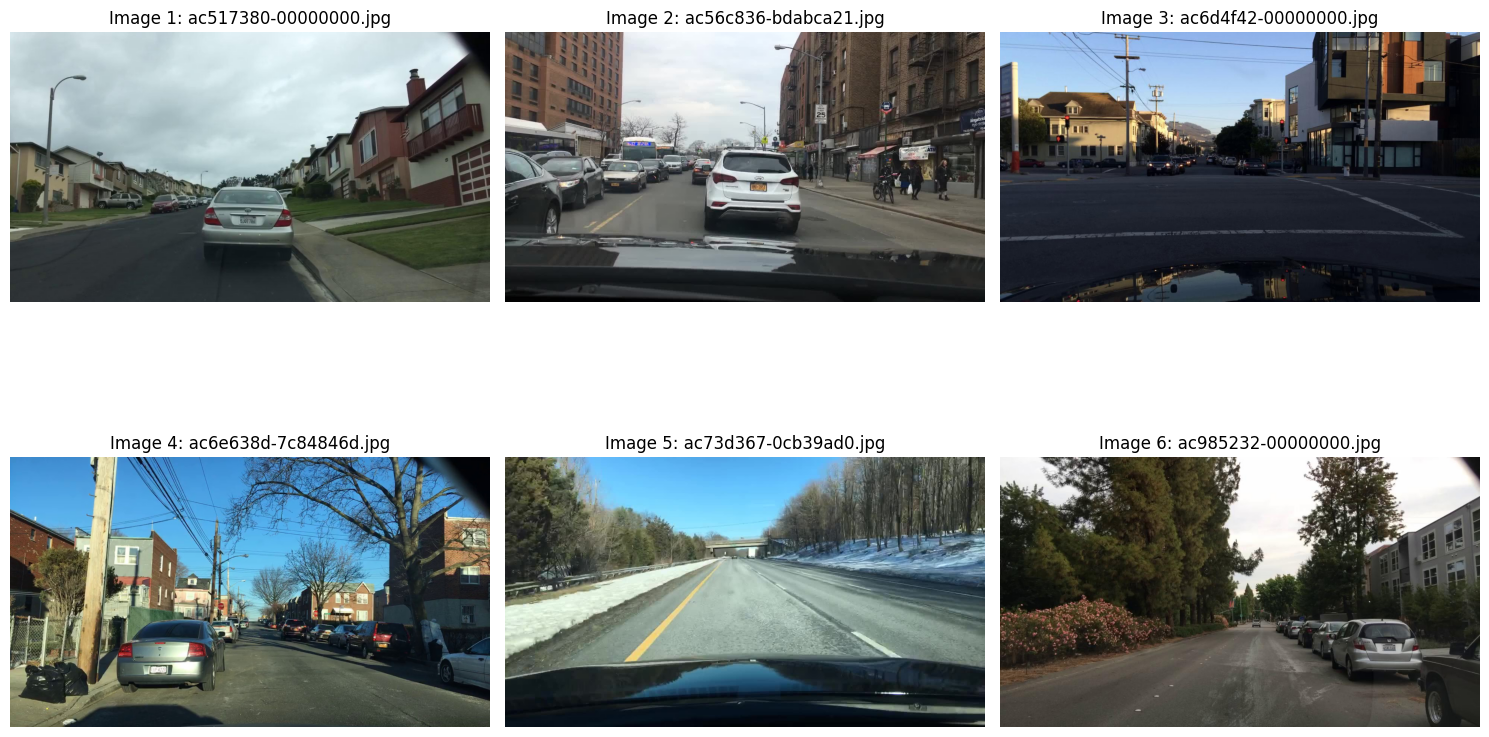


Displayed 6 sample images from the dataset


In [4]:

from src.fetch_dataset import display_sample_images

display_sample_images(OUTPUT_DIR)


---

# 2. Data Augmentation for VAE-based Image Reconstruction

For training a robust Variational Autoencoder (VAE) model for image reconstruction, we need to create augmented versions of our dataset with various degradations. The model will learn to reconstruct clean images from these degraded inputs using a probabilistic latent space.

In [5]:
# %pip install opencv-python-headless albumentations scikit-image numpy pillow matplotlib tqdm

## 2.1 Test Augmentation Classes on Sample Images

Visualize different augmentation techniques on sample images.

GroundTruthAugmentor and ImageDegradator classes created!
- GroundTruthAugmentor: Handles stretch, rotation, zoom, and colorimetry
- ImageDegradator: Handles noise, blur, occlusion, scratches, and rain drops


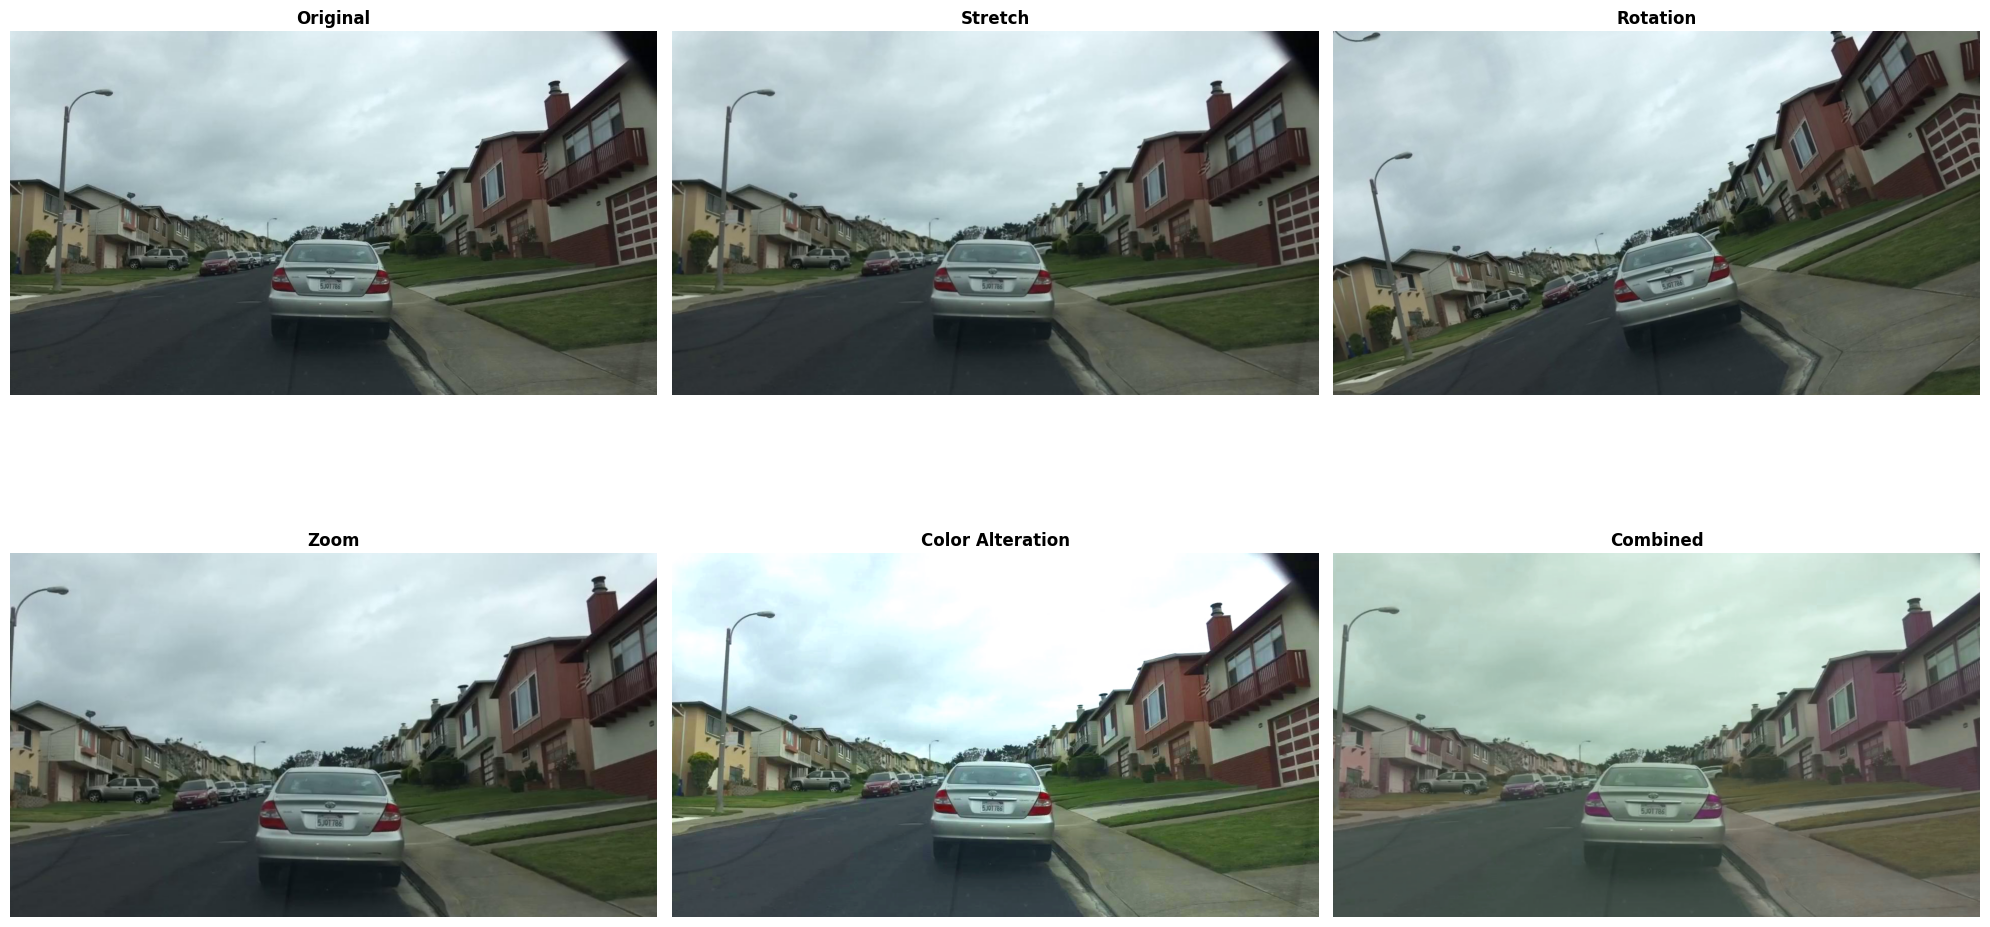

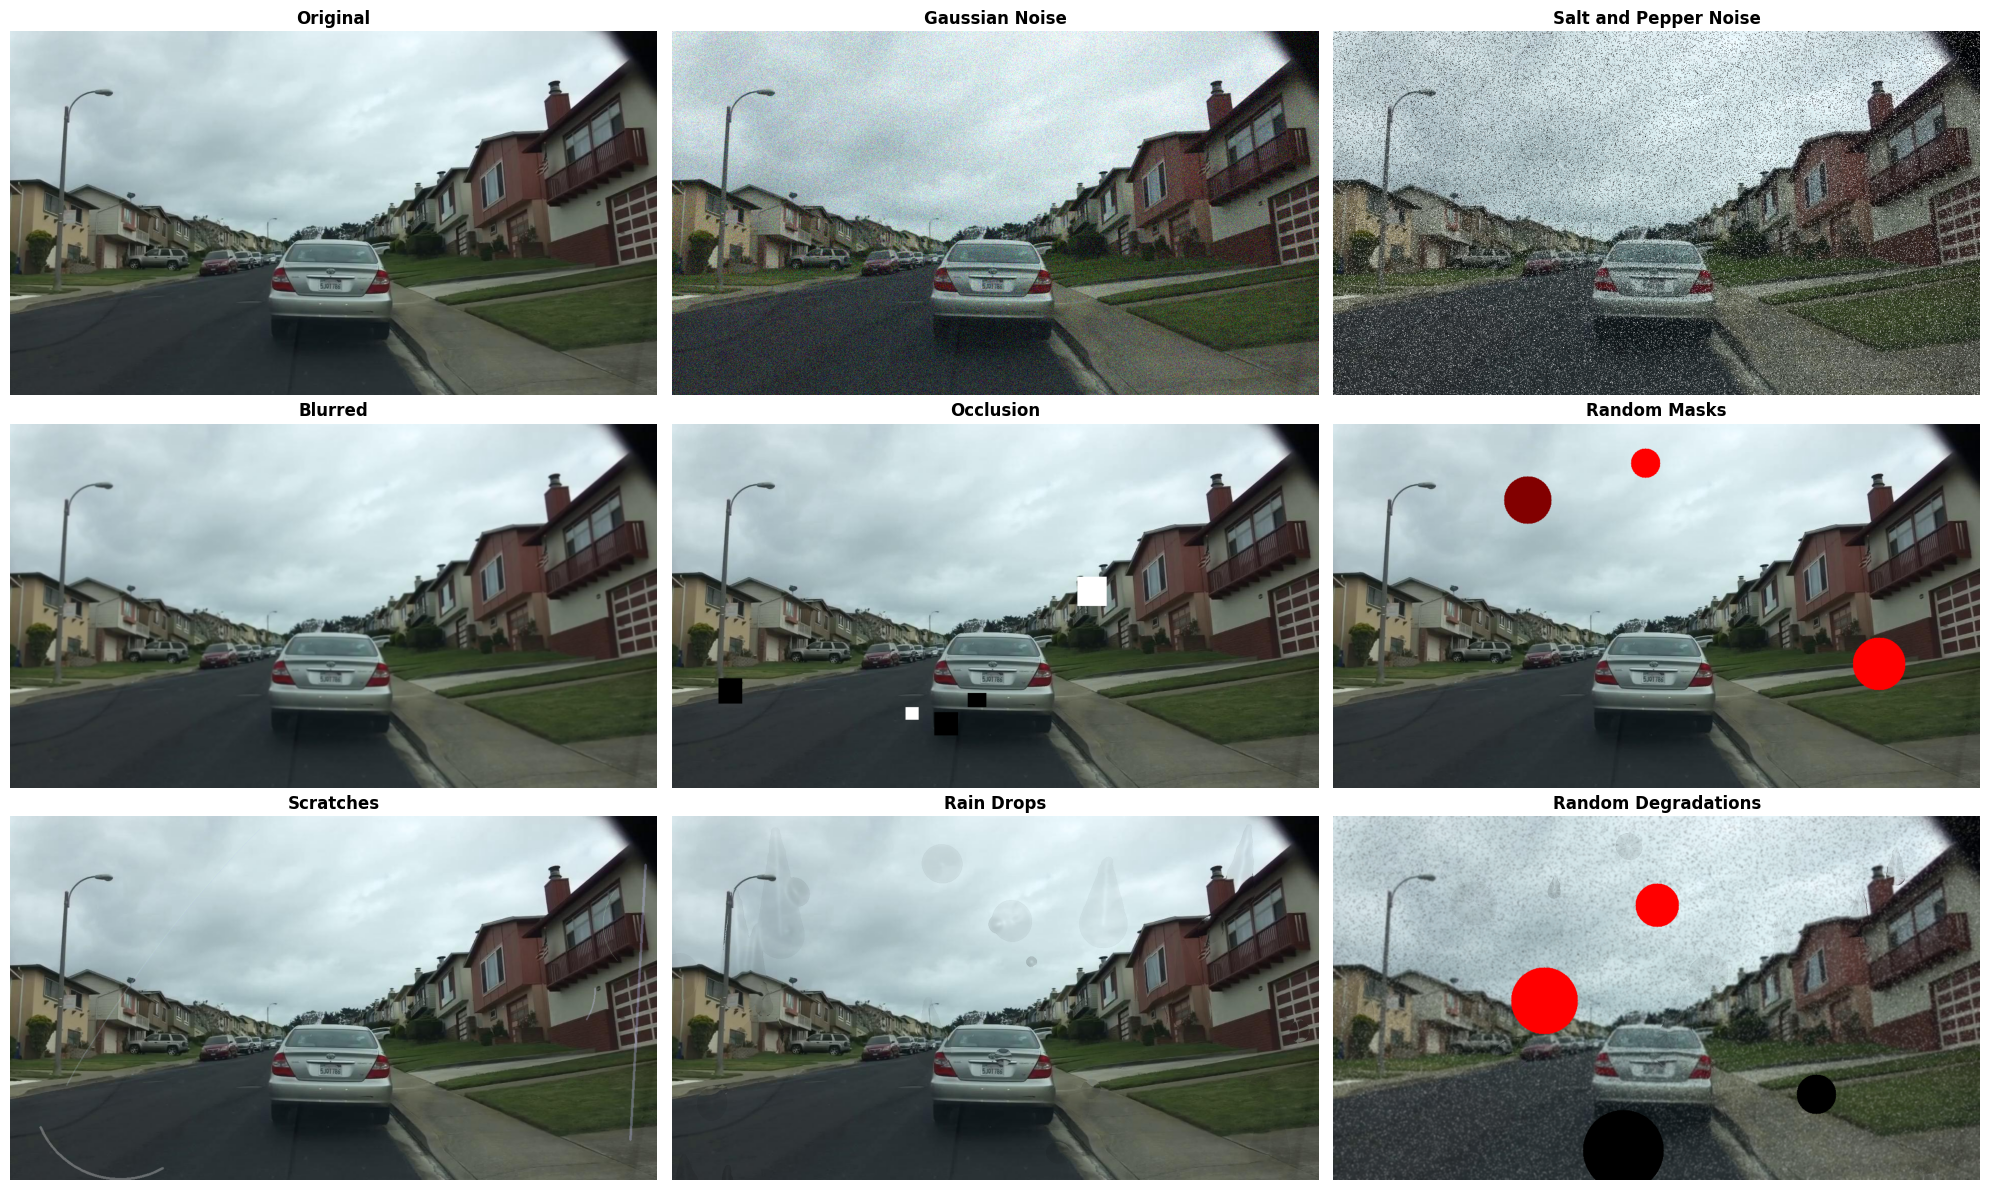

In [6]:
from PIL import Image

import os
import glob

from src.augmentation import GroundTruthAugmentor, ImageDegradator

all_images: list[str] = glob.glob(os.path.join(OUTPUT_DIR, '**', '*.jpg'), recursive=True)

# Create instances
augmentor = GroundTruthAugmentor()
degradator = ImageDegradator()
print("GroundTruthAugmentor and ImageDegradator classes created!")
print("- GroundTruthAugmentor: Handles stretch, rotation, zoom, and colorimetry")
print("- ImageDegradator: Handles noise, blur, occlusion, scratches, and rain drops")

augmentor.demo(Image.open(all_images[0]))
degradator.demo(Image.open(all_images[0]))

## 2.2 Generate Augmented Dataset

Generate augmented image pairs (degraded, clean) for GAN training.

In [7]:
from src.augmentation import generate_dataset

# Configuration
AUGMENTED_DIR = f"{ROOT_DIR}/data_augmented"

# Create augmented dataset using parallel processing on all CPU cores
clean_dir, degraded_dir, total_generated = generate_dataset(
    all_images,
    AUGMENTED_DIR,
    num_augmentations_per_image=0,
    num_degradations_per_image=1,
    force_regenerate=False,
    n_jobs=None  # None = use all available CPU cores
)

Augmentation Configuration:
  - Output directory: .//data_augmented
  - Available CPU cores: 24
  - Ground truth augmentations per image: 0
  - Degradations per ground truth image: 1
Expected size: 10000
Clean existing: 10000
Degraded existing: 10000
✓ Dataset already exists (10000 images).


## 2.2.1 Visualize Augmented Image Pairs

Display some examples of degraded/clean image pairs from the augmented dataset.

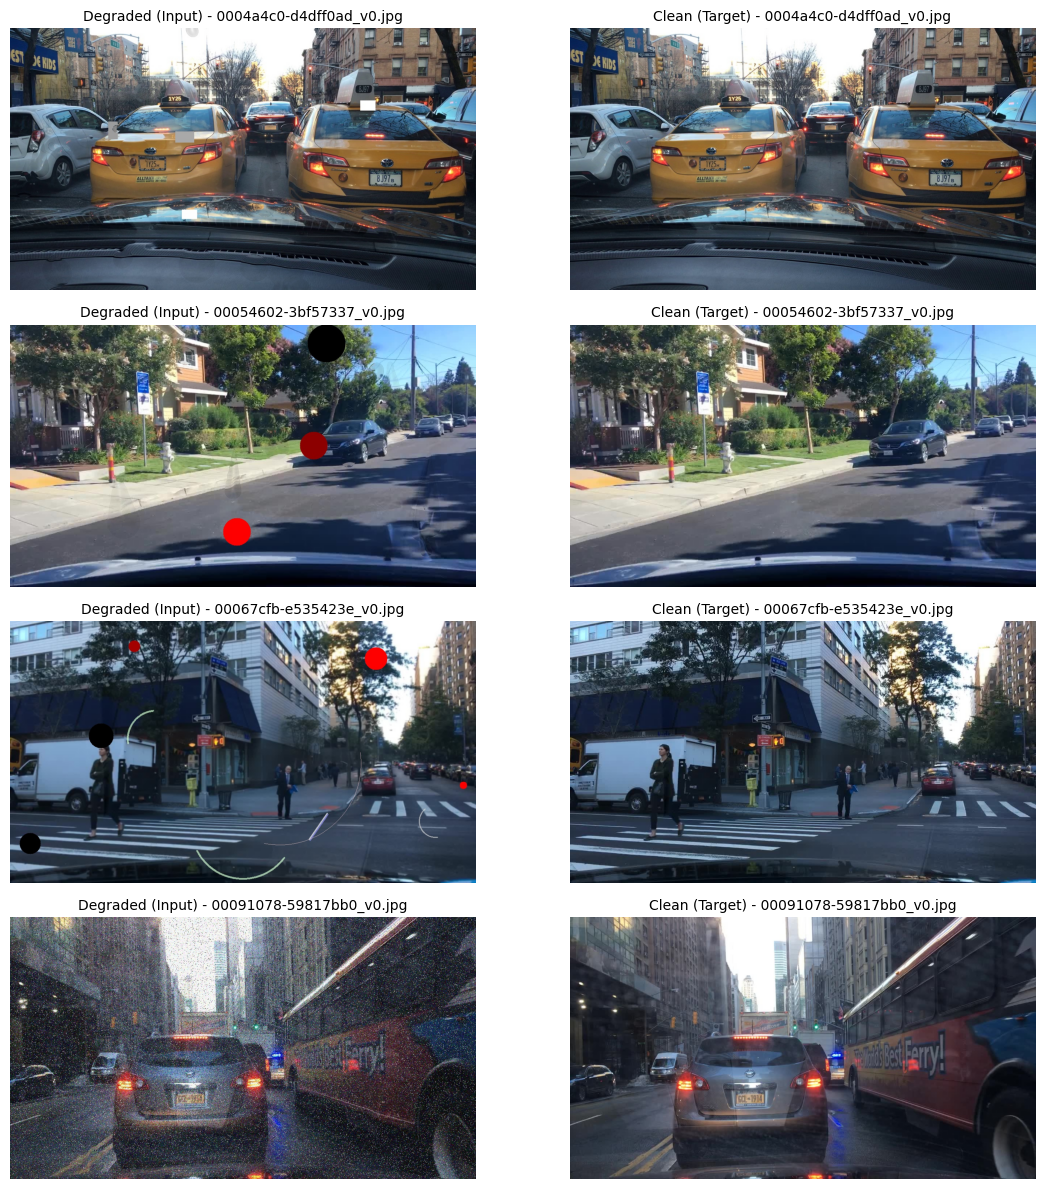

✓ Displayed 4 image pairs from augmented dataset

Dataset Summary:
  - Total degraded images: 10000
  - Total clean images: 10000
  - Ready for GAN training!


In [8]:
import matplotlib.pyplot as plt

# Get sample augmented images
degraded_images = sorted(glob.glob(os.path.join(degraded_dir, '*.jpg')))
clean_images = sorted(glob.glob(os.path.join(clean_dir, '*.jpg')))

if len(degraded_images) > 0:
    # Display 4 pairs
    num_pairs = min(4, len(degraded_images))

    fig, axes = plt.subplots(num_pairs, 2, figsize=(12, num_pairs * 3))
    if num_pairs == 1:
        axes = axes.reshape(1, -1)

    for i in range(num_pairs):
        # Load degraded (input)
        degraded_img = Image.open(degraded_images[i])
        axes[i, 0].imshow(degraded_img)
        axes[i, 0].set_title(f'Degraded (Input) - {os.path.basename(degraded_images[i])}',
                            fontsize=10)
        axes[i, 0].axis('off')

        # Load clean (target)
        clean_img = Image.open(clean_images[i])
        axes[i, 1].imshow(clean_img)
        axes[i, 1].set_title(f'Clean (Target) - {os.path.basename(clean_images[i])}',
                            fontsize=10)
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

    print(f"✓ Displayed {num_pairs} image pairs from augmented dataset")
    print(f"\nDataset Summary:")
    print(f"  - Total degraded images: {len(degraded_images)}")
    print(f"  - Total clean images: {len(clean_images)}")
    print(f"  - Ready for GAN training!")
else:
    print("No augmented images found")

# 3. Config tensorflow

In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow.keras.backend as K

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

# Set memory growth for GPU (if available)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"✓ GPU memory growth enabled for {len(gpus)} GPU(s)")
    except RuntimeError as e:
        print(e)

print("✓ TensorFlow imported successfully")

2025-11-28 15:27:41.764254: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-11-28 15:27:41.812302: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-11-28 15:27:41.830218: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-11-28 15:27:41.835885: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-11-28 15:27:41.857700: I tensorflow/core/platform/cpu_feature_guar

TensorFlow version: 2.17.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✓ GPU memory growth enabled for 1 GPU(s)
✓ TensorFlow imported successfully


I0000 00:00:1764343663.673655    1736 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1764343663.715283    1736 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1764343663.715325    1736 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


## 4. Data Pipeline Setup

Create TensorFlow data pipeline for loading and preprocessing image pairs.

In [10]:
from src.create_dataset import create_dataset

# Configuration
IMG_HEIGHT = 256
IMG_WIDTH = 256
BATCH_SIZE = 4
BUFFER_SIZE = 1000

# Create train dataset
train_dataset = create_dataset(degraded_dir, clean_dir, IMG_HEIGHT, IMG_WIDTH, BATCH_SIZE, BUFFER_SIZE, shuffle=True)

print(f"✓ Dataset created successfully")
print(f"  - Image size: {IMG_HEIGHT}x{IMG_WIDTH}")
print(f"  - Batch size: {BATCH_SIZE}")
print(f"  - Data range: [-1, 1]")

Found 10000 image pairs
✓ Dataset created successfully
  - Image size: 256x256
  - Batch size: 4
  - Data range: [-1, 1]


I0000 00:00:1764343667.659422    1736 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1764343667.659488    1736 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1764343667.659510    1736 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1764343667.936609    1736 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1764343667.936677    1736 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-11-28

# VAE-based Image Reconstruction Model

Build a Variational Autoencoder (VAE) to reconstruct clean images from degraded inputs using a probabilistic approach with latent space modeling.

## 13. Install TensorFlow and Setup

Install TensorFlow and required dependencies for building the VAE model.

In [11]:
%pip install tensorflow


[notice] A new release of pip is available: 24.1.2 -> 25.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [12]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
import os
import time
from IPython.display import clear_output

print(f"TensorFlow version: {tf.__version__}")

# Check for GPU
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    print(f"GPUs available: {len(gpus)}")
    for gpu in gpus:
        print(f"  - {gpu}")
    try:
        # Enable memory growth
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("✓ GPU memory growth enabled")
    except RuntimeError as e:
        print(f"GPU configuration error: {e}")
else:
    print("No GPU detected - using CPU")

print("✓ TensorFlow setup complete")

TensorFlow version: 2.17.0
GPUs available: 1
  - PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
✓ GPU memory growth enabled
✓ TensorFlow setup complete


## 14. VAE Configuration

Set up the VAE hyperparameters and configuration.

In [13]:
# VAE Hyperparameters
IMG_CHANNELS = 3
LATENT_DIM = 512  # Dimension of the latent space
EPOCHS = 100

# Loss weights
RECONSTRUCTION_WEIGHT = 1.0  # Weight for perceptual loss
KL_WEIGHT_MAX = 0.5  # Maximum beta for beta-VAE (< 1 for better reconstruction)
KL_ANNEAL_EPOCHS = 30  # Number of epochs to anneal KL weight

# VGG Perceptual Loss layers
VGG_LAYERS = ['block1_conv2', 'block2_conv2', 'block3_conv3', 'block4_conv3']
PERCEPTUAL_WEIGHTS = [1.0, 1.0, 1.0, 1.0]  # Weights for each VGG layer

# Model save paths
VAE_MODEL_PATH = f"{MODEL_DIR}/vae_model.keras"
ENCODER_MODEL_PATH = f"{MODEL_DIR}/encoder_model.keras"
DECODER_MODEL_PATH = f"{MODEL_DIR}/decoder_model.keras"

# Training configuration
LOAD_PRETRAINED_MODELS = False  # Set to True to load saved models

print("✓ VAE Configuration:")
print(f"  - Image size: {IMG_HEIGHT}×{IMG_WIDTH}×{IMG_CHANNELS}")
print(f"  - Latent dimension: {LATENT_DIM}")
print(f"  - Batch size: {BATCH_SIZE}")
print(f"  - Epochs: {EPOCHS}")
print(f"  - Reconstruction weight: {RECONSTRUCTION_WEIGHT}")
print(f"  - KL weight max (beta): {KL_WEIGHT_MAX}")
print(f"  - KL annealing epochs: {KL_ANNEAL_EPOCHS}")
print(f"  - VGG layers for perceptual loss: {VGG_LAYERS}")
print(f"  - Model save path: {VAE_MODEL_PATH}")
print(f"  - Load pretrained: {LOAD_PRETRAINED_MODELS}")

✓ VAE Configuration:
  - Image size: 256×256×3
  - Latent dimension: 512
  - Batch size: 4
  - Epochs: 100
  - Reconstruction weight: 1.0
  - KL weight max (beta): 0.5
  - KL annealing epochs: 30
  - VGG layers for perceptual loss: ['block1_conv2', 'block2_conv2', 'block3_conv3', 'block4_conv3']
  - Model save path: ./models//vae_model.keras
  - Load pretrained: False


## 14.1 VGG Perceptual Loss Model

Build a VGG-based perceptual loss model for better reconstruction quality.

In [14]:
def build_vgg_perceptual_model():
    """
    Build VGG19 model for perceptual loss computation

    Uses intermediate layers from VGG19 to compute perceptual similarity
    between reconstructed and target images.
    """
    # Load VGG19 pretrained on ImageNet
    vgg = keras.applications.VGG19(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)
    )
    vgg.trainable = False

    # Get outputs from specified layers
    outputs = [vgg.get_layer(name).output for name in VGG_LAYERS]

    # Create model that outputs intermediate features
    perceptual_model = keras.Model(inputs=vgg.input, outputs=outputs, name='vgg_perceptual')

    print("✓ VGG Perceptual Model built successfully")
    print(f"  - Layers used: {VGG_LAYERS}")
    print(f"  - Output shapes: {[o.shape for o in outputs]}")

    return perceptual_model

# Build VGG model for perceptual loss
vgg_perceptual = build_vgg_perceptual_model()

def preprocess_for_vgg(images):
    """
    Preprocess images for VGG (convert from [-1,1] to VGG format)
    """
    # Convert from [-1, 1] to [0, 255]
    images = (images + 1.0) * 127.5
    # Apply VGG preprocessing (BGR conversion and mean subtraction)
    return keras.applications.vgg19.preprocess_input(images)

def perceptual_loss(y_true, y_pred, vgg_model):
    """
    Compute perceptual loss using VGG features

    Args:
        y_true: Target images [-1, 1]
        y_pred: Reconstructed images [-1, 1]
        vgg_model: VGG perceptual model

    Returns:
        Weighted sum of feature losses
    """
    # Preprocess for VGG
    y_true_vgg = preprocess_for_vgg(y_true)
    y_pred_vgg = preprocess_for_vgg(y_pred)

    # Get features from VGG
    true_features = vgg_model(y_true_vgg)
    pred_features = vgg_model(y_pred_vgg)

    # Compute weighted loss for each layer
    total_loss = 0.0
    for i, (true_feat, pred_feat) in enumerate(zip(true_features, pred_features)):
        layer_loss = tf.reduce_mean(tf.square(true_feat - pred_feat))
        total_loss += PERCEPTUAL_WEIGHTS[i] * layer_loss

    return total_loss

print("✓ Perceptual loss functions defined")

✓ VGG Perceptual Model built successfully
  - Layers used: ['block1_conv2', 'block2_conv2', 'block3_conv3', 'block4_conv3']
  - Output shapes: [(None, 256, 256, 64), (None, 128, 128, 128), (None, 64, 64, 256), (None, 32, 32, 512)]
✓ Perceptual loss functions defined


## 15. VAE Encoder Architecture

Build the encoder that maps degraded images to latent distribution parameters (mean and log variance).

In [15]:
class ResNetBlock(layers.Layer):
    """
    Residual Block for improved gradient flow
    """
    def __init__(self, filters, kernel_size=3, **kwargs):
        super(ResNetBlock, self).__init__(**kwargs)
        self.filters = filters
        self.kernel_size = kernel_size

    def build(self, input_shape):
        self.conv1 = layers.Conv2D(self.filters, self.kernel_size, padding='same')
        self.bn1 = layers.BatchNormalization()
        self.conv2 = layers.Conv2D(self.filters, self.kernel_size, padding='same')
        self.bn2 = layers.BatchNormalization()

        # Projection shortcut if channels don't match
        if input_shape[-1] != self.filters:
            self.shortcut = layers.Conv2D(self.filters, 1, padding='same')
        else:
            self.shortcut = None
        super().build(input_shape)

    def call(self, inputs, training=None):
        x = self.conv1(inputs)
        x = self.bn1(x, training=training)
        x = tf.nn.relu(x)
        x = self.conv2(x)
        x = self.bn2(x, training=training)

        shortcut = self.shortcut(inputs) if self.shortcut else inputs
        return tf.nn.relu(x + shortcut)

    def get_config(self):
        config = super().get_config()
        config.update({
            'filters': self.filters,
            'kernel_size': self.kernel_size
        })
        return config


def build_encoder():
    """
    Build VAE Encoder with Skip Connections

    Takes degraded images and outputs:
    - mu (mean): The mean of the latent distribution
    - log_var (log variance): The log variance of the latent distribution
    - skip_features: Feature maps for skip connections to decoder

    Architecture:
    - Convolutional layers with ResNet blocks for feature extraction
    - Progressive downsampling
    - Skip connections at each resolution level
    - Final dense layers for mu and log_var
    """
    inputs = keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS), name='encoder_input')

    # Encoder layers - Progressive downsampling with skip connections
    # Level 1: 256 -> 128
    x = layers.Conv2D(64, 4, strides=2, padding='same')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = ResNetBlock(64)(x)
    skip1 = x  # 128x128x64

    # Level 2: 128 -> 64
    x = layers.Conv2D(128, 4, strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = ResNetBlock(128)(x)
    skip2 = x  # 64x64x128

    # Level 3: 64 -> 32
    x = layers.Conv2D(256, 4, strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = ResNetBlock(256)(x)
    skip3 = x  # 32x32x256

    # Level 4: 32 -> 16
    x = layers.Conv2D(512, 4, strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = ResNetBlock(512)(x)
    skip4 = x  # 16x16x512

    # Level 5: 16 -> 8
    x = layers.Conv2D(512, 4, strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = ResNetBlock(512)(x)  # 8x8x512

    # Flatten and create latent representation
    x = layers.Flatten()(x)
    x = layers.Dense(1024, activation='relu')(x)
    x = layers.BatchNormalization()(x)

    # Latent distribution parameters
    z_mean = layers.Dense(LATENT_DIM, name='z_mean')(x)
    z_log_var = layers.Dense(LATENT_DIM, name='z_log_var')(x)

    # Return model with skip connections as additional outputs
    return keras.Model(inputs, [z_mean, z_log_var, skip1, skip2, skip3, skip4], name='vae_encoder')

def sampling(args):
    """
    Reparameterization trick for VAE

    Instead of sampling from Q(z|X), sample from a standard normal distribution
    and transform using the learned parameters:
    z = mu + sigma * epsilon, where epsilon ~ N(0,1)
    """
    z_mean, z_log_var = args
    epsilon = tf.random.normal(shape=tf.shape(z_mean))
    return z_mean + tf.exp(0.5 * z_log_var) * epsilon

# Build encoder
encoder = build_encoder()

print("✓ VAE Encoder with Skip Connections built successfully")
print(f"  - Input shape: {encoder.input.shape}")
print(f"  - Output shapes (z_mean, z_log_var, skip1, skip2, skip3, skip4):")
for i, output in enumerate(encoder.outputs):
    print(f"    - Output {i+1}: {output.shape}")
print(f"  - Total parameters: {encoder.count_params():,}")

# Display encoder architecture
encoder.summary()

✓ VAE Encoder with Skip Connections built successfully
  - Input shape: (None, 256, 256, 3)
  - Output shapes (z_mean, z_log_var, skip1, skip2, skip3, skip4):
    - Output 1: (None, 512)
    - Output 2: (None, 512)
    - Output 3: (None, 128, 128, 64)
    - Output 4: (None, 64, 64, 128)
    - Output 5: (None, 32, 32, 256)
    - Output 6: (None, 16, 16, 512)
  - Total parameters: 52,566,592


Model: "vae_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      3,136 │ encoder_input[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block       │ (None, 128, 128,  │     74,368 │ re_lu[0][0]       │
│ (ResNetBlock)       │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │    131,200 │ res_net_block[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_1     │ (None, 64, 64,    │    296,192 │ re_lu_1[0][0]     │
│ (ResNetBlock)       │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │    524,544 │ res_net_block_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │      1,024 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_2     │ (None, 32, 32,    │  1,182,208 │ re_lu_2[0][0]     │
│ (ResNetBlock)       │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 16, 16,    │  2,097,664 │ res_net_block_2[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │      2,048 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_3     │ (None, 16, 16,    │  4,723,712 │ re_lu_3[0][0]   

 Total params: 52,566,592 (200.53 MB)

 Trainable params: 52,555,712 (200.48 MB)

 Non-trainable params: 10,880 (42.50 KB)

## 16. VAE Decoder Architecture

Build the decoder that reconstructs clean images from latent space representations.

In [16]:
class SubPixelConv2D(layers.Layer):
    """
    Sub-Pixel Convolution (Pixel Shuffle) for upsampling

    More effective than transposed convolution, reduces checkerboard artifacts.
    Rearranges elements from depth into spatial dimensions.
    """
    def __init__(self, scale=2, filters=None, **kwargs):
        super(SubPixelConv2D, self).__init__(**kwargs)
        self.scale = scale
        self.filters = filters

    def build(self, input_shape):
        # Conv to expand channels for pixel shuffle
        # Output channels = filters * scale^2
        out_channels = (self.filters if self.filters else input_shape[-1]) * (self.scale ** 2)
        self.conv = layers.Conv2D(out_channels, 3, padding='same')
        super().build(input_shape)

    def call(self, inputs):
        x = self.conv(inputs)
        # Pixel shuffle: (B, H, W, C*r^2) -> (B, H*r, W*r, C)
        return tf.nn.depth_to_space(x, self.scale)

    def get_config(self):
        config = super().get_config()
        config.update({
            'scale': self.scale,
            'filters': self.filters
        })
        return config


class UpsampleBlock(layers.Layer):
    """
    Upsampling block using UpSampling2D + Conv2D + SubPixelConv2D

    Combines multiple upsampling strategies for better quality
    """
    def __init__(self, filters, use_subpixel=True, **kwargs):
        super(UpsampleBlock, self).__init__(**kwargs)
        self.filters = filters
        self.use_subpixel = use_subpixel

    def build(self, input_shape):
        if self.use_subpixel:
            # SubPixel convolution path
            self.subpixel = SubPixelConv2D(scale=2, filters=self.filters)
        else:
            # Traditional upsampling path
            self.upsample = layers.UpSampling2D(size=2, interpolation='bilinear')
            self.conv = layers.Conv2D(self.filters, 3, padding='same')

        self.bn = layers.BatchNormalization()
        super().build(input_shape)

    def call(self, inputs, training=None):
        if self.use_subpixel:
            x = self.subpixel(inputs)
        else:
            x = self.upsample(inputs)
            x = self.conv(x)
        x = self.bn(x, training=training)
        return tf.nn.relu(x)

    def get_config(self):
        config = super().get_config()
        config.update({
            'filters': self.filters,
            'use_subpixel': self.use_subpixel
        })
        return config


def build_decoder():
    """
    Build VAE Decoder with Skip Connections, UpSampling + SubPixelConv2D and ResNet blocks

    Takes latent space representations and skip connection features,
    then reconstructs clean images using modern upsampling techniques.

    Architecture:
    - Dense layers to expand latent vector
    - Reshape to feature maps
    - Progressive upsampling with SubPixelConv2D and ResNet blocks
    - Skip connections from encoder at each resolution level
    - Final layer outputs reconstructed image
    """
    # Inputs
    latent_inputs = keras.Input(shape=(LATENT_DIM,), name='decoder_latent_input')
    skip1_input = keras.Input(shape=(128, 128, 64), name='skip1_input')   # 128x128x64
    skip2_input = keras.Input(shape=(64, 64, 128), name='skip2_input')    # 64x64x128
    skip3_input = keras.Input(shape=(32, 32, 256), name='skip3_input')    # 32x32x256
    skip4_input = keras.Input(shape=(16, 16, 512), name='skip4_input')    # 16x16x512

    # Dense layers to expand latent representation
    x = layers.Dense(8 * 8 * 512, activation='relu')(latent_inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Reshape((8, 8, 512))(x)  # 8x8x512
    x = ResNetBlock(512)(x)

    # Level 1: 8 -> 16 + skip4
    x = UpsampleBlock(512, use_subpixel=True)(x)  # 16x16x512
    x = layers.Concatenate()([x, skip4_input])     # 16x16x1024
    x = layers.Conv2D(512, 1, padding='same')(x)   # Reduce channels
    x = ResNetBlock(512)(x)

    # Level 2: 16 -> 32 + skip3
    x = UpsampleBlock(256, use_subpixel=True)(x)  # 32x32x256
    x = layers.Concatenate()([x, skip3_input])     # 32x32x512
    x = layers.Conv2D(256, 1, padding='same')(x)   # Reduce channels
    x = ResNetBlock(256)(x)

    # Level 3: 32 -> 64 + skip2
    x = UpsampleBlock(128, use_subpixel=True)(x)  # 64x64x128
    x = layers.Concatenate()([x, skip2_input])     # 64x64x256
    x = layers.Conv2D(128, 1, padding='same')(x)   # Reduce channels
    x = ResNetBlock(128)(x)

    # Level 4: 64 -> 128 + skip1
    x = UpsampleBlock(64, use_subpixel=True)(x)   # 128x128x64
    x = layers.Concatenate()([x, skip1_input])     # 128x128x128
    x = layers.Conv2D(64, 1, padding='same')(x)    # Reduce channels
    x = ResNetBlock(64)(x)

    # Level 5: 128 -> 256 (final upsampling, no skip)
    x = UpsampleBlock(32, use_subpixel=True)(x)   # 256x256x32
    x = ResNetBlock(32)(x)

    # Final layer - reconstruct RGB image
    outputs = layers.Conv2D(IMG_CHANNELS, 3, padding='same', activation='tanh',
                           name='decoder_output')(x)  # 256x256x3

    return keras.Model(
        [latent_inputs, skip1_input, skip2_input, skip3_input, skip4_input],
        outputs,
        name='vae_decoder'
    )

# Build decoder
decoder = build_decoder()

print("✓ VAE Decoder with Skip Connections and SubPixelConv2D built successfully")
print(f"  - Latent input shape: {decoder.inputs[0].shape}")
print(f"  - Skip connection inputs: {[inp.shape for inp in decoder.inputs[1:]]}")
print(f"  - Output shape: {decoder.output.shape}")
print(f"  - Total parameters: {decoder.count_params():,}")

# Display decoder architecture
decoder.summary()

✓ VAE Decoder with Skip Connections and SubPixelConv2D built successfully
  - Latent input shape: (None, 512)
  - Skip connection inputs: [(None, 128, 128, 64), (None, 64, 64, 128), (None, 32, 32, 256), (None, 16, 16, 512)]
  - Output shape: (None, 256, 256, 3)
  - Total parameters: 44,370,147


Model: "vae_decoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ decoder_latent_inp… │ (None, 512)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32768)     │ 16,809,984 │ decoder_latent_i… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32768)     │    131,072 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 8, 8, 512) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_5     │ (None, 8, 8, 512) │  4,723,712 │ reshape[0][0]     │
│ (ResNetBlock)       │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ upsample_block      │ (None, 16, 16,    │  9,441,280 │ res_net_block_5[… │
│ (UpsampleBlock)     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip4_input         │ (None, 16, 16,    │          0 │ -                 │
│ (InputLayer)        │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ upsample_block[0… │
│ (Concatenate)       │ 1024)             │            │ skip4_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 16, 16,    │    524,800 │ concatenate[0][0] │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_6     │ (None, 16, 16,    │  4,723,712 │ conv2d_18[0][0]   │
│ (ResNetBlock)       │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ upsample_block_1    │ (None, 32, 32,    │  4,720,640 │ res_net_block_6[… │
│ (UpsampleBlock)     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip3_input         │ (None, 32, 32,    │          0 │ -                 │
│ (InputLayer)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 32, 32,    │          0 │ upsample_block_1… │
│ (Concatenate)       │ 512)              │            │ skip3_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 32, 32,    │    131,328 │ concatenate_1[0]… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_7     │ (None, 32, 32,    │  1,182,208 │ conv2d_22[0][0]   │
│ (ResNetBlock)       │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ upsample_block_2    │ (None, 64, 64,    │  1,180,672 │ res_net_block_7[… │
│ (UpsampleBlock)     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip2_input         │ (None, 64, 64,    │          0 │ -                 │
│ (InputLayer)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 44,370,147 (169.26 MB)

 Trainable params: 44,296,611 (168.98 MB)

 Non-trainable params: 73,536 (287.25 KB)

## 17. Complete VAE Model

Combine encoder and decoder into a complete VAE model with reparameterization trick.

In [17]:
class VAE(keras.Model):
    """
    Variational Autoencoder for Image Reconstruction with:
    - Skip connections between encoder and decoder
    - VGG perceptual loss instead of MSE
    - KL annealing with beta-VAE (beta < 1)
    - SubPixelConv2D upsampling
    - ResNet blocks for improved gradient flow
    """

    def __init__(self, encoder, decoder, vgg_model, **kwargs):
        super(VAE, self).__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.vgg_model = vgg_model

        # KL annealing: start at 0 and increase to KL_WEIGHT_MAX
        self.kl_weight = tf.Variable(0.0, trainable=False, name='kl_weight')
        self.current_epoch = tf.Variable(0, trainable=False, name='current_epoch')

        # Metrics
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")
        self.perceptual_loss_tracker = keras.metrics.Mean(name="perceptual_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
            self.perceptual_loss_tracker,
        ]

    def update_kl_weight(self, epoch):
        """
        Update KL weight using linear annealing

        Starts at 0 and linearly increases to KL_WEIGHT_MAX over KL_ANNEAL_EPOCHS
        """
        if epoch < KL_ANNEAL_EPOCHS:
            new_weight = (epoch / KL_ANNEAL_EPOCHS) * KL_WEIGHT_MAX
        else:
            new_weight = KL_WEIGHT_MAX
        self.kl_weight.assign(new_weight)
        self.current_epoch.assign(epoch)
        return new_weight

    def train_step(self, data):
        """Custom training step for VAE with perceptual loss and KL annealing"""
        degraded_images, clean_images = data

        # Cast to float32 for training stability
        degraded_images = tf.cast(degraded_images, tf.float32)
        clean_images = tf.cast(clean_images, tf.float32)

        with tf.GradientTape() as tape:
            # Encode - get latent params and skip connections
            z_mean, z_log_var, skip1, skip2, skip3, skip4 = self.encoder(degraded_images, training=True)

            # Sample from latent space
            z = sampling([z_mean, z_log_var])

            # Decode with skip connections
            reconstruction = self.decoder([z, skip1, skip2, skip3, skip4], training=True)

            # Calculate perceptual loss (VGG-based)
            perceptual = perceptual_loss(clean_images, reconstruction, self.vgg_model)
            reconstruction_loss = perceptual * RECONSTRUCTION_WEIGHT

            # Add small L1 loss for pixel-level accuracy
            l1_loss = tf.reduce_mean(tf.abs(clean_images - reconstruction)) * 10.0
            reconstruction_loss = reconstruction_loss + l1_loss

            # KL divergence loss with annealing
            kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
            kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))

            # Apply current KL weight (beta-VAE with annealing)
            weighted_kl_loss = kl_loss * self.kl_weight

            total_loss = reconstruction_loss + weighted_kl_loss

        # Compute gradients and update weights
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        # Update metrics
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(weighted_kl_loss)
        self.perceptual_loss_tracker.update_state(perceptual)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
            "perceptual_loss": self.perceptual_loss_tracker.result(),
            "kl_weight": self.kl_weight,
        }

    def call(self, inputs, training=False):
        """Forward pass through VAE"""
        z_mean, z_log_var, skip1, skip2, skip3, skip4 = self.encoder(inputs, training=training)
        z = sampling([z_mean, z_log_var])
        return self.decoder([z, skip1, skip2, skip3, skip4], training=training)

# Create VAE model with VGG perceptual model
vae = VAE(encoder, decoder, vgg_perceptual)

print("✓ Complete VAE model created with:")
print(f"  - Skip connections: ✓")
print(f"  - SubPixelConv2D upsampling: ✓")
print(f"  - ResNet blocks: ✓")
print(f"  - VGG Perceptual loss: ✓")
print(f"  - KL annealing (beta-VAE): ✓")
print(f"  - Encoder parameters: {encoder.count_params():,}")
print(f"  - Decoder parameters: {decoder.count_params():,}")
print(f"  - Total VAE parameters: {encoder.count_params() + decoder.count_params():,}")
print(f"  - Latent dimension: {LATENT_DIM}")
print(f"  - Max KL weight (beta): {KL_WEIGHT_MAX}")
print(f"  - KL annealing epochs: {KL_ANNEAL_EPOCHS}")

✓ Complete VAE model created with:
  - Skip connections: ✓
  - SubPixelConv2D upsampling: ✓
  - ResNet blocks: ✓
  - VGG Perceptual loss: ✓
  - KL annealing (beta-VAE): ✓
  - Encoder parameters: 52,566,592
  - Decoder parameters: 44,370,147
  - Total VAE parameters: 96,936,739
  - Latent dimension: 512
  - Max KL weight (beta): 0.5
  - KL annealing epochs: 30


## 18. VAE Compilation and Optimizer Setup

Configure the optimizer and compile the VAE model for training.

In [18]:
# Optimizer configuration
optimizer = keras.optimizers.Adam(learning_rate=1e-3, beta_1=0.5)

# Compile VAE
vae.compile(optimizer=optimizer)

# Checkpoint configuration
checkpoint_dir = './vae_training_checkpoints'
os.makedirs(checkpoint_dir, exist_ok=True)
checkpoint_prefix = os.path.join(checkpoint_dir, "vae_ckpt")

checkpoint = tf.train.Checkpoint(
    optimizer=optimizer,
    encoder=encoder,
    decoder=decoder,
    vae=vae
)

print("✓ VAE compiled and configured")
print(f"  - Optimizer: Adam (lr=1e-4, beta_1=0.5)")
print(f"  - Checkpoint directory: {checkpoint_dir}")
print("  - Model ready for training!")

# Optional: Restore from checkpoint
# Uncomment to restore from previous training
# if tf.train.latest_checkpoint(checkpoint_dir):
#     checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))
#     print(f"✓ Restored from checkpoint: {tf.train.latest_checkpoint(checkpoint_dir)}")
# else:
#     print("ℹ No checkpoint found - starting fresh training")

✓ VAE compiled and configured
  - Optimizer: Adam (lr=1e-4, beta_1=0.5)
  - Checkpoint directory: ./vae_training_checkpoints
  - Model ready for training!


## 19. VAE Visualization Functions

Create functions to visualize VAE training progress and reconstructions.

In [19]:
def visualize_vae_reconstruction(vae_model, test_degraded, test_clean, num_samples=5, save_path=None):
    """
    Visualize VAE reconstructions (Style matching image_reconstructor.ipynb)

    Args:
        vae_model: Trained VAE model
        test_degraded: Degraded input images
        test_clean: Clean target images
        num_samples: Number of samples to display
        save_path: Optional path to save the figure
    """
    # Generate reconstructions using full forward pass with skip connections
    reconstructions = vae_model(test_degraded, training=False)

    # Convert from [-1, 1] to [0, 1] for display
    test_degraded_display = (test_degraded + 1) / 2.0
    test_clean_display = (test_clean + 1) / 2.0
    reconstructions_display = (reconstructions + 1) / 2.0

    # Limit number of samples
    num_samples = min(num_samples, test_degraded.shape[0])

    # Create figure with 3 columns: Degraded | Reconstructed | Original
    fig, axes = plt.subplots(num_samples, 3, figsize=(18, num_samples * 6))

    # Handle single row case
    if num_samples == 1:
        axes = axes.reshape(1, -1)

    # Column titles
    column_titles = ['Degraded Image', 'Reconstructed Image', 'Original Image']

    for i in range(num_samples):
        for j, title in enumerate(column_titles):
            # Select the appropriate image
            if j == 0:
                img = test_degraded_display[i]
            elif j == 1:
                img = reconstructions_display[i]
            else:
                img = test_clean_display[i]

            # Display image
            axes[i, j].imshow(img)

            # Add title only to first row
            if i == 0:
                axes[i, j].set_title(title, fontsize=16, fontweight='bold', pad=20)

            # Add row label on the left
            if j == 0:
                axes[i, j].set_ylabel(f'Sample {i+1}', fontsize=14, fontweight='bold', rotation=0,
                                     labelpad=60, va='center')

            axes[i, j].axis('off')

    plt.tight_layout()
    plt.subplots_adjust(wspace=0.05, hspace=0.1)

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"✓ Saved visualization to {save_path}")

    plt.show()

def plot_latent_space_2d(vae_model, test_data, labels=None, num_samples=1000):
    """
    Plot 2D visualization of latent space (if latent_dim >= 2)

    Args:
        vae_model: Trained VAE model
        test_data: Test images
        labels: Optional labels for coloring
        num_samples: Number of samples to plot
    """
    if LATENT_DIM < 2:
        print("Cannot visualize latent space: dimension < 2")
        return

    # Encode test data (get only z_mean, ignore skip connections)
    z_mean, z_log_var, _, _, _, _ = vae_model.encoder(test_data[:num_samples])

    # Plot first 2 dimensions of latent space
    plt.figure(figsize=(10, 8))
    if labels is not None:
        scatter = plt.scatter(z_mean[:, 0], z_mean[:, 1], c=labels[:num_samples],
                            cmap='viridis', alpha=0.7)
        plt.colorbar(scatter)
    else:
        plt.scatter(z_mean[:, 0], z_mean[:, 1], alpha=0.7)

    plt.xlabel('Latent Dimension 1')
    plt.ylabel('Latent Dimension 2')
    plt.title('VAE Latent Space Visualization (First 2 Dimensions)')
    plt.grid(True, alpha=0.3)
    plt.show()

def generate_new_images(vae_model, num_images=8, reference_images=None):
    """
    Generate new images by sampling from the latent space

    Args:
        vae_model: Trained VAE model
        num_images: Number of images to generate
        reference_images: Optional reference images for skip connections
    """
    # Sample random points from standard normal distribution
    random_latent = tf.random.normal(shape=(num_images, LATENT_DIM))

    # For skip connections, we need reference images
    # If not provided, use zeros (will still work but quality may vary)
    if reference_images is not None:
        # Get skip connections from reference images
        _, _, skip1, skip2, skip3, skip4 = vae_model.encoder(reference_images[:num_images])
    else:
        # Create zero skip connections
        skip1 = tf.zeros((num_images, 128, 128, 64))
        skip2 = tf.zeros((num_images, 64, 64, 128))
        skip3 = tf.zeros((num_images, 32, 32, 256))
        skip4 = tf.zeros((num_images, 16, 16, 512))

    # Decode with skip connections
    generated_images = vae_model.decoder([random_latent, skip1, skip2, skip3, skip4])

    # Convert to display format
    generated_display = (generated_images + 1) / 2.0

    # Display generated images
    cols = 4
    rows = (num_images + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 4))
    if rows == 1:
        axes = axes.reshape(1, -1)

    for i in range(rows * cols):
        row, col = i // cols, i % cols

        if i < num_images:
            axes[row, col].imshow(generated_display[i])
            axes[row, col].set_title(f'Generated {i+1}')
        else:
            axes[row, col].axis('off')

        axes[row, col].axis('off')

    plt.tight_layout()
    plt.suptitle('Images Generated from Random Latent Vectors', fontsize=16, y=1.02)
    plt.show()

print("✓ VAE visualization functions defined")
print("  Functions available:")
print("  - visualize_vae_reconstruction(): Compare input, reconstruction, and target")
print("  - plot_latent_space_2d(): Visualize latent space distribution")
print("  - generate_new_images(): Generate new images from random latent vectors")

✓ VAE visualization functions defined
  Functions available:
  - visualize_vae_reconstruction(): Compare input, reconstruction, and target
  - plot_latent_space_2d(): Visualize latent space distribution
  - generate_new_images(): Generate new images from random latent vectors


## Save and Load VAE Models

Functions to save and load the trained VAE models.

In [20]:
def save_vae_models(vae_model, encoder_model, decoder_model, save_dir=None):
    """
    Save VAE models to disk

    Args:
        vae_model: Complete VAE model
        encoder_model: Encoder model
        decoder_model: Decoder model
        save_dir: Directory to save models (uses MODEL_DIR if None)
    """
    if save_dir is None:
        save_dir = MODEL_DIR

    os.makedirs(save_dir, exist_ok=True)

    encoder_path = os.path.join(save_dir, "vae_encoder.keras")
    decoder_path = os.path.join(save_dir, "vae_decoder.keras")

    try:
        # Ensure models are built (if needed)
        encoder_model.build((None, IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS))
        decoder_model.build([
            (None, LATENT_DIM),
            (None, 128, 128, 64),
            (None, 64, 64, 128),
            (None, 32, 32, 256),
            (None, 16, 16, 512)
        ])

        # Save individual components with custom objects
        custom_objects = {
            'ResNetBlock': ResNetBlock,
            'SubPixelConv2D': SubPixelConv2D,
            'UpsampleBlock': UpsampleBlock
        }

        encoder_model.save(encoder_path)
        decoder_model.save(decoder_path)

        # Save complete VAE weights
        vae_weights_path = os.path.join(save_dir, "vae_weights.weights.h5")
        vae_model.save_weights(vae_weights_path)

        # Save KL weight for resuming training
        kl_state_path = os.path.join(save_dir, "kl_state.npz")
        np.savez(kl_state_path,
                 kl_weight=float(vae_model.kl_weight.numpy()),
                 current_epoch=int(vae_model.current_epoch.numpy()))

        print("✓ VAE models saved successfully:")
        print(f"  - Encoder: {encoder_path}")
        print(f"  - Decoder: {decoder_path}")
        print(f"  - VAE weights: {vae_weights_path}")
        print(f"  - KL state: {kl_state_path}")

        return {
            'encoder': encoder_path,
            'decoder': decoder_path,
            'vae_weights': vae_weights_path,
            'kl_state': kl_state_path
        }

    except Exception as e:
        print(f"❌ Error saving models: {e}")
        import traceback
        traceback.print_exc()
        return None

def load_vae_models(save_dir=None):
    """
    Load VAE models from disk

    Args:
        save_dir: Directory containing saved models

    Returns:
        Tuple of (encoder, decoder, vae) or None if loading fails
    """
    if save_dir is None:
        save_dir = MODEL_DIR

    encoder_path = os.path.join(save_dir, "vae_encoder.keras")
    decoder_path = os.path.join(save_dir, "vae_decoder.keras")
    vae_weights_path = os.path.join(save_dir, "vae_weights.weights.h5")
    kl_state_path = os.path.join(save_dir, "kl_state.npz")

    # Custom objects for loading
    custom_objects = {
        'ResNetBlock': ResNetBlock,
        'SubPixelConv2D': SubPixelConv2D,
        'UpsampleBlock': UpsampleBlock
    }

    try:
        # Load encoder and decoder
        if os.path.exists(encoder_path) and os.path.exists(decoder_path):
            loaded_encoder = keras.models.load_model(encoder_path, custom_objects=custom_objects)
            loaded_decoder = keras.models.load_model(decoder_path, custom_objects=custom_objects)

            # Recreate VAE with loaded components and VGG model
            loaded_vae = VAE(loaded_encoder, loaded_decoder, vgg_perceptual)

            # Load VAE weights if available
            if os.path.exists(vae_weights_path):
                # Build the model first by calling it once
                dummy_input = tf.random.normal((1, IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS))
                _ = loaded_vae(dummy_input)

                # Now load the weights
                loaded_vae.load_weights(vae_weights_path)
                print(f"✓ VAE weights loaded from {os.path.basename(vae_weights_path)}")

            # Load KL state if available
            if os.path.exists(kl_state_path):
                kl_state = np.load(kl_state_path)
                loaded_vae.kl_weight.assign(kl_state['kl_weight'])
                loaded_vae.current_epoch.assign(int(kl_state['current_epoch']))
                print(f"✓ KL state restored: weight={kl_state['kl_weight']:.4f}, epoch={kl_state['current_epoch']}")

            # Compile the loaded VAE
            optimizer = keras.optimizers.Adam(learning_rate=1e-4, beta_1=0.5)
            loaded_vae.compile(optimizer=optimizer)

            print("✓ VAE models loaded successfully:")
            print(f"  - Encoder parameters: {loaded_encoder.count_params():,}")
            print(f"  - Decoder parameters: {loaded_decoder.count_params():,}")
            print(f"  - Total parameters: {loaded_encoder.count_params() + loaded_decoder.count_params():,}")

            return loaded_encoder, loaded_decoder, loaded_vae

        else:
            print("❌ Model files not found:")
            print(f"  - Encoder: {encoder_path} ({'✓' if os.path.exists(encoder_path) else '❌'})")
            print(f"  - Decoder: {decoder_path} ({'✓' if os.path.exists(decoder_path) else '❌'})")
            return None

    except Exception as e:
        print(f"❌ Error loading models: {e}")
        import traceback
        traceback.print_exc()
        return None

# Example usage (uncomment to save after training):
# save_paths = save_vae_models(vae, encoder, decoder)

# Example usage (uncomment to load saved models):
try:
    loaded = load_vae_models()
    assert loaded is not None, "No model could be loaded"
    encoder = loaded[0]
    decoder = loaded[1]
    vae = loaded[2]
except Exception as e:
    print("Failed to load saved model:", e)
    print("Will use freshly initialized models")

print("✓ VAE save/load functions defined")
print("Available functions:")
print("  - save_vae_models(vae, encoder, decoder, save_dir): Save trained models")
print("  - load_vae_models(save_dir): Load saved models")
print()
print("Usage after training:")
print("  save_paths = save_vae_models(vae, encoder, decoder)")
print()
print("Usage to load saved models:")
print("  loaded_encoder, loaded_decoder, loaded_vae = load_vae_models()")

2025-11-28 15:27:56.886426: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:531] Loaded cuDNN version 8906
W0000 00:00:1764343676.973158    1736 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1764343677.013581    1736 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1764343677.050800    1736 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1764343677.051947    1736 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1764343677.056491    1736 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1764343677.059173    1736 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1764343677.063985    1736 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1764343677.069927    1736 gpu_t

✓ VAE weights loaded from vae_weights.weights.h5
✓ KL state restored: weight=0.0000, epoch=0
✓ VAE models loaded successfully:
  - Encoder parameters: 52,566,592
  - Decoder parameters: 44,370,147
  - Total parameters: 96,936,739
✓ VAE save/load functions defined
Available functions:
  - save_vae_models(vae, encoder, decoder, save_dir): Save trained models
  - load_vae_models(save_dir): Load saved models

Usage after training:
  save_paths = save_vae_models(vae, encoder, decoder)

Usage to load saved models:
  loaded_encoder, loaded_decoder, loaded_vae = load_vae_models()


## 20. VAE Training Loop

Train the VAE model with monitoring and visualization.

In [21]:
def train_vae(vae_model, train_dataset, epochs, checkpoint_interval=5, visualization_interval=1, start_epoch=0):
    """
    Train the VAE model with KL annealing

    Args:
        vae_model: VAE model to train
        train_dataset: Training dataset
        epochs: Number of epochs to train
        checkpoint_interval: Save checkpoint every N epochs
        visualization_interval: Show visualizations every N epochs
        start_epoch: Starting epoch (for resuming training)
    """
    # Create output directories
    sample_dir = './vae_training_samples'
    os.makedirs(sample_dir, exist_ok=True)

    # Training history
    history = {
        'total_loss': [],
        'reconstruction_loss': [],
        'kl_loss': [],
        'perceptual_loss': [],
        'kl_weight': []
    }

    # Get test batch for visualization
    try:
        test_degraded, test_clean = next(iter(train_dataset))
    except:
        print("Warning: Could not get test batch for visualization")
        test_degraded, test_clean = None, None

    print(f"Starting VAE training for {epochs} epochs (starting from epoch {start_epoch + 1})...")
    print(f"KL Annealing: 0 → {KL_WEIGHT_MAX} over {KL_ANNEAL_EPOCHS} epochs")
    print("="*60)

    for epoch in range(start_epoch, start_epoch + epochs):
        epoch_start_time = time.time()

        # Update KL weight for this epoch (annealing)
        current_kl_weight = vae_model.update_kl_weight(epoch)

        # Training metrics for this epoch
        epoch_losses = {'total_loss': [], 'reconstruction_loss': [], 'kl_loss': [], 'perceptual_loss': []}

        print(f"\nEpoch {epoch + 1}/{start_epoch + epochs}")
        print(f"  KL weight (beta): {current_kl_weight:.4f}")
        print("-" * 40)

        # Train on all batches
        for step, (degraded_batch, clean_batch) in enumerate(train_dataset):
            # Train step
            metrics = vae_model.train_step([degraded_batch, clean_batch])

            # Collect metrics
            epoch_losses['total_loss'].append(metrics['loss'].numpy())
            epoch_losses['reconstruction_loss'].append(metrics['reconstruction_loss'].numpy())
            epoch_losses['kl_loss'].append(metrics['kl_loss'].numpy())
            epoch_losses['perceptual_loss'].append(metrics['perceptual_loss'].numpy())

            # Print progress every 10 steps
            if step % 10 == 0:
                elapsed = time.time() - epoch_start_time
                print(f"  Step {step}/{len(train_dataset)}: "
                      f"Loss={metrics['loss']:.4f}, "
                      f"Perceptual={metrics['perceptual_loss']:.4f}, "
                      f"KL={metrics['kl_loss']:.4f}, "
                      f"β={current_kl_weight:.3f}, "
                      f"Time={elapsed:.1f}s")

        # Calculate epoch averages
        avg_total_loss = np.mean(epoch_losses['total_loss'])
        avg_recon_loss = np.mean(epoch_losses['reconstruction_loss'])
        avg_kl_loss = np.mean(epoch_losses['kl_loss'])
        avg_perceptual_loss = np.mean(epoch_losses['perceptual_loss'])

        # Update history
        history['total_loss'].append(avg_total_loss)
        history['reconstruction_loss'].append(avg_recon_loss)
        history['kl_loss'].append(avg_kl_loss)
        history['perceptual_loss'].append(avg_perceptual_loss)
        history['kl_weight'].append(current_kl_weight)

        # Epoch summary
        epoch_time = time.time() - epoch_start_time

        # Save checkpoint
        if (epoch + 1) % checkpoint_interval == 0:
            checkpoint.save(file_prefix=checkpoint_prefix)
            print(f"  ✓ Checkpoint saved at epoch {epoch + 1}")

        # Epoch summary
        print(f"Epoch {epoch + 1} Summary:")
        print(f"    Total Loss: {avg_total_loss:.4f}")
        print(f"    Perceptual Loss: {avg_perceptual_loss:.4f}")
        print(f"    Reconstruction Loss: {avg_recon_loss:.4f}")
        print(f"    KL Loss: {avg_kl_loss:.4f}")
        print(f"    KL Weight (beta): {current_kl_weight:.4f}")
        print(f"    Time: {epoch_time:.1f}s")

        # Visualization
        if test_degraded is not None:
            print(f"  📊 Generating visualization for epoch {epoch + 1}")
            save_path = f"{sample_dir}/reconstruction_epoch_{epoch + 1:03d}.png"

            num_sample: int = 10
            # Cast to float32 for visualization
            test_degraded_viz = tf.cast(test_degraded[:num_sample], tf.float32)
            test_clean_viz = tf.cast(test_clean[:num_sample], tf.float32)

            visualize_vae_reconstruction(
                vae_model,
                test_degraded_viz,
                test_clean_viz,
                num_samples=num_sample,
                save_path=save_path
            )

        # Save model at each epoch
        save_vae_models(vae_model, vae_model.encoder, vae_model.decoder)
        print(f"  ✓ Model saved at epoch {epoch + 1}")
        print(f"Epoch {epoch + 1}/{epochs} completed")

    print("\n🎉 VAE Training completed!")
    print(f"Final metrics:")
    print(f"  - Total Loss: {history['total_loss'][-1]:.4f}")
    print(f"  - Perceptual Loss: {history['perceptual_loss'][-1]:.4f}")
    print(f"  - Reconstruction Loss: {history['reconstruction_loss'][-1]:.4f}")
    print(f"  - KL Loss: {history['kl_loss'][-1]:.4f}")
    print(f"  - Final KL Weight (beta): {history['kl_weight'][-1]:.4f}")

    # Plot training history
    plot_training_history(history)

    return history

def plot_training_history(history):
    """Plot VAE training history including KL annealing"""
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # Total loss
    axes[0, 0].plot(history['total_loss'], 'b-', linewidth=2, label='Total Loss')
    axes[0, 0].set_title('Total Loss', fontsize=14, fontweight='bold')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].legend()

    # Perceptual loss
    axes[0, 1].plot(history['perceptual_loss'], 'g-', linewidth=2, label='Perceptual Loss (VGG)')
    axes[0, 1].set_title('Perceptual Loss (VGG)', fontsize=14, fontweight='bold')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Loss')
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].legend()

    # KL loss  Step
    axes[1, 0].plot(history['kl_loss'], 'r-', linewidth=2, label='KL Divergence Loss')
    axes[1, 0].set_title('KL Divergence Loss (weighted)', fontsize=14, fontweight='bold')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Loss')
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].legend()

    # KL weight (beta) annealing
    axes[1, 1].plot(history['kl_weight'], 'm-', linewidth=2, label='KL Weight (β)')
    axes[1, 1].axhline(y=KL_WEIGHT_MAX, color='r', linestyle='--', alpha=0.5, label=f'Max β = {KL_WEIGHT_MAX}')
    axes[1, 1].axvline(x=KL_ANNEAL_EPOCHS, color='g', linestyle='--', alpha=0.5, label=f'Anneal end = {KL_ANNEAL_EPOCHS}')
    axes[1, 1].set_title('KL Weight (β) Annealing Schedule', fontsize=14, fontweight='bold')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('β')
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].legend()

    plt.tight_layout()
    plt.suptitle('VAE Training History with KL Annealing & VGG Perceptual Loss', fontsize=16, y=1.02)
    plt.show()

print("✓ VAE training functions defined")
print("  Use train_vae(vae, train_dataset, epochs) to start training")
print("  Training will include:")
print("  - KL annealing (beta: 0 → {:.2f} over {} epochs)".format(KL_WEIGHT_MAX, KL_ANNEAL_EPOCHS))
print("  - VGG perceptual loss")
print("  - Progress monitoring")
print("  - Automatic checkpointing")
print("  - Periodic visualizations")
print("  - Training history plots")

✓ VAE training functions defined
  Use train_vae(vae, train_dataset, epochs) to start training
  Training will include:
  - KL annealing (beta: 0 → 0.50 over 30 epochs)
  - VGG perceptual loss
  - Progress monitoring
  - Automatic checkpointing
  - Periodic visualizations
  - Training history plots


## 21. Start VAE Training

Execute the training loop with the configured parameters.

In [ ]:
# Make sure train_dataset is available before training
# (This assumes you have run the data preparation cells earlier)

# Note: Uncomment the following line to start training
# Adjust epochs as needed - start with a small number for testing

training_history = train_vae(
    vae_model=vae,
    train_dataset=train_dataset,
    epochs=50,  # Start with 50 epochs, increase for better results
    checkpoint_interval=5,
    visualization_interval=10
)

print("Training parameters:")
print(f"  - Batch size: {BATCH_SIZE}")
print(f"  - Latent dimension: {LATENT_DIM}")
print(f"  - Reconstruction weight: {RECONSTRUCTION_WEIGHT}")
print(f"  - KL weight: {KL_WEIGHT_MAX}")
print(f"  - Learning rate: 1e-4")
print()
print("Recommended training progression:")
print("  - Start with 20-50 epochs to test")
print("  - If results look good, continue with 100-200 epochs")
print("  - Monitor reconstruction quality during training")

Starting VAE training for 50 epochs (starting from epoch 1)...
KL Annealing: 0 → 0.5 over 30 epochs

Epoch 1/50
  KL weight (beta): 0.0000
----------------------------------------


2025-11-28 15:28:01.589180: E tensorflow/core/util/util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.
W0000 00:00:1764343681.734416    1736 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1764343681.735851    1736 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1764343681.739952    1736 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1764343681.742795    1736 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1764343681.745841    1736 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1764343681.748787    1736 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1764343681.787439    1736 gpu_timer.cc:114] Skipping the delay kernel, measuremen

  Step 0/2500: Loss=101711.1953, Perceptual=101710.0469, KL=0.0000, β=0.000, Time=8.7s
  Step 10/2500: Loss=74948.6328, Perceptual=74947.2812, KL=0.0000, β=0.000, Time=15.6s
  Step 20/2500: Loss=75886.3594, Perceptual=75885.1328, KL=0.0000, β=0.000, Time=22.7s
  Step 30/2500: Loss=75855.8203, Perceptual=75854.6484, KL=0.0000, β=0.000, Time=30.2s
  Step 40/2500: Loss=75385.3281, Perceptual=75384.1797, KL=0.0000, β=0.000, Time=37.3s
  Step 50/2500: Loss=76679.1719, Perceptual=76678.0312, KL=0.0000, β=0.000, Time=44.2s
  Step 60/2500: Loss=76920.2578, Perceptual=76919.1172, KL=0.0000, β=0.000, Time=51.3s
  Step 70/2500: Loss=75747.6797, Perceptual=75746.5625, KL=0.0000, β=0.000, Time=58.5s
  Step 80/2500: Loss=75440.7344, Perceptual=75439.5859, KL=0.0000, β=0.000, Time=65.4s
  Step 90/2500: Loss=76074.9375, Perceptual=76073.7891, KL=0.0000, β=0.000, Time=72.8s


In [ ]:
# Load trained model (Optional)
# Uncomment the following lines to load a previously trained model

# loaded_encoder, loaded_decoder, loaded_vae = load_vae_models()
# if loaded_vae is not None:
#     encoder = loaded_encoder
#     decoder = loaded_decoder
#     vae = loaded_vae
#     print("✓ Model loaded and ready for use")
# else:
#     print("❌ Failed to load model")

## 23. VAE Demonstration and Testing

Test the VAE capabilities with various visualization and generation techniques.

In [ ]:
# Test VAE functionality (run after training or loading a trained model)

def demonstrate_vae_capabilities(vae_model, encoder_model, decoder_model, test_data=None):
    """
    Comprehensive demonstration of VAE capabilities

    Args:
        vae_model: Trained VAE model
        encoder_model: Trained encoder
        decoder_model: Trained decoder
        test_data: Optional test data tuple (degraded, clean)
    """
    print("🎯 VAE Demonstration Starting...")
    print("="*50)

    # 1. Model Information
    print("\n📊 Model Information:")
    print(f"  - Encoder parameters: {encoder_model.count_params():,}")
    print(f"  - Decoder parameters: {decoder_model.count_params():,}")
    print(f"  - Total parameters: {encoder_model.count_params() + decoder_model.count_params():,}")
    print(f"  - Latent dimension: {LATENT_DIM}")
    print(f"  - Current KL weight (beta): {float(vae_model.kl_weight.numpy()):.4f}")
    print(f"  - Max KL weight: {KL_WEIGHT_MAX}")
    print(f"  - Features: Skip connections, SubPixelConv2D, ResNet blocks, VGG loss")

    if test_data is not None:
        degraded_batch, clean_batch = test_data

        # 2. Reconstruction demonstration
        print("\n🔄 Reconstruction Demonstration:")
        visualize_vae_reconstruction(vae_model, degraded_batch[:4], clean_batch[:4], num_samples=4)

        # 3. Latent space analysis
        print("\n🌌 Latent Space Analysis:")
        if LATENT_DIM >= 2:
            plot_latent_space_2d(vae_model, degraded_batch[:100])
        else:
            print("  Latent dimension too low for 2D visualization")

        # 4. Encoding-Decoding process visualization
        print("\n🧠 Encoding-Decoding Process with Skip Connections:")
        sample_image = degraded_batch[:1]
        z_mean, z_log_var, skip1, skip2, skip3, skip4 = encoder_model(sample_image)
        z_sample = sampling([z_mean, z_log_var])
        reconstruction = decoder_model([z_sample, skip1, skip2, skip3, skip4])

        print(f"  Input shape: {sample_image.shape}")
        print(f"  Latent mean shape: {z_mean.shape}")
        print(f"  Latent log_var shape: {z_log_var.shape}")
        print(f"  Sampled latent shape: {z_sample.shape}")
        print(f"  Skip connection shapes:")
        print(f"    - Skip1: {skip1.shape}")
        print(f"    - Skip2: {skip2.shape}")
        print(f"    - Skip3: {skip3.shape}")
        print(f"    - Skip4: {skip4.shape}")
        print(f"  Reconstruction shape: {reconstruction.shape}")

        # Show latent statistics
        print(f"  Latent mean range: [{z_mean.numpy().min():.3f}, {z_mean.numpy().max():.3f}]")
        print(f"  Latent std range: [{tf.exp(0.5 * z_log_var).numpy().min():.3f}, {tf.exp(0.5 * z_log_var).numpy().max():.3f}]")

    # 5. Generate new images (with reference for skip connections)
    print("\n🎨 Image Generation from Random Latent Vectors:")
    if test_data is not None:
        generate_new_images(vae_model, num_images=8, reference_images=degraded_batch)
    else:
        generate_new_images(vae_model, num_images=8)

    # 6. Latent space interpolation (if we have test data)
    if test_data is not None:
        print("\n🌊 Latent Space Interpolation:")
        interpolate_in_latent_space(vae_model, degraded_batch[:2])

    print("\n✅ VAE Demonstration Complete!")

def interpolate_in_latent_space(vae_model, images, num_steps=8):
    """
    Interpolate between two images in latent space (with skip connections)

    Args:
        vae_model: Trained VAE
        images: Batch of at least 2 images
        num_steps: Number of interpolation steps
    """
    if len(images) < 2:
        print("Need at least 2 images for interpolation")
        return

    # Encode first two images (including skip connections)
    z_mean1, z_log_var1, skip1_1, skip2_1, skip3_1, skip4_1 = vae_model.encoder(images[:1])
    z_mean2, z_log_var2, skip1_2, skip2_2, skip3_2, skip4_2 = vae_model.encoder(images[1:2])

    # Use means for interpolation (more stable than sampling)
    z1 = z_mean1
    z2 = z_mean2

    # Create interpolation
    decoded_interpolations = []
    for i in range(num_steps):
        alpha = i / (num_steps - 1)
        z_interp = (1 - alpha) * z1 + alpha * z2

        # Interpolate skip connections too
        skip1_interp = (1 - alpha) * skip1_1 + alpha * skip1_2
        skip2_interp = (1 - alpha) * skip2_1 + alpha * skip2_2
        skip3_interp = (1 - alpha) * skip3_1 + alpha * skip3_2
        skip4_interp = (1 - alpha) * skip4_1 + alpha * skip4_2

        decoded = vae_model.decoder([z_interp, skip1_interp, skip2_interp, skip3_interp, skip4_interp])
        decoded_interpolations.append(decoded)

    # Stack all interpolations
    decoded_interpolations = tf.concat(decoded_interpolations, axis=0)

    # Display results
    fig, axes = plt.subplots(2, num_steps, figsize=(num_steps * 3, 6))

    # Original images
    for i in range(num_steps):
        if i == 0:
            img = (images[0] + 1) / 2.0
            axes[0, i].set_title(f'Original 1', fontweight='bold')
        elif i == num_steps - 1:
            img = (images[1] + 1) / 2.0
            axes[0, i].set_title(f'Original 2', fontweight='bold')
        else:
            # Show interpolation progress
            alpha = i / (num_steps - 1)
            img1 = (images[0] + 1) / 2.0
            img2 = (images[1] + 1.0) / 2.0
            img = (1 - alpha) * img1 + alpha * img2
            axes[0, i].set_title(f'Mix {alpha:.1f}', fontsize=10)

        axes[0, i].imshow(img)
        axes[0, i].axis('off')

    # Interpolated reconstructions
    for i in range(num_steps):
        img = (decoded_interpolations[i] + 1) / 2.0
        axes[1, i].imshow(img)
        axes[1, i].set_title(f'Step {i+1}', fontsize=10)
        axes[1, i].axis('off')

    # Add row labels
    axes[0, 0].set_ylabel('Input Space\nInterpolation', fontsize=12, fontweight='bold', rotation=0, labelpad=80, va='center')
    axes[1, 0].set_ylabel('Latent Space\nInterpolation', fontsize=12, fontweight='bold', rotation=0, labelpad=80, va='center')

    plt.tight_layout()
    plt.suptitle('Latent Space Interpolation (with Skip Connections)', fontsize=16, y=1.02)
    plt.show()

# Example usage (uncomment after training):
# if 'vae' in globals() and 'train_dataset' in globals():
#     test_batch = next(iter(train_dataset))
#     demonstrate_vae_capabilities(vae, encoder, decoder, test_batch)

print("✅ VAE demonstration functions ready!")
print("\nTo run the demonstration after training:")
print("  test_batch = next(iter(train_dataset))")
print("  demonstrate_vae_capabilities(vae, encoder, decoder, test_batch)")
print("\nThis will show:")
print("  1. Model information (including beta-VAE weight)")
print("  2. Reconstruction examples (with skip connections)")
print("  3. Latent space visualization")
print("  4. Encoding-decoding process details (with skip info)")
print("  5. Generated images from random latent vectors")
print("  6. Latent space interpolation (with skip connection interpolation)")

✅ VAE demonstration functions ready!
\nTo run the demonstration after training:
  test_batch = next(iter(train_dataset))
  demonstrate_vae_capabilities(vae, encoder, decoder, test_batch)
\nThis will show:
  1. Model information
  2. Reconstruction examples
  3. Latent space visualization
  4. Encoding-decoding process details
  5. Generated images from random latent vectors
  6. Latent space interpolation between images
